
<div style="background-color:#dff2e1; padding:16px; border-radius:8px;">
<h1 style="margin-bottom:4px;">Industrial Data Analytics</h1>
<h2 style="margin-top:4px;">Practical Session 4 - Fundamental Statistical Concepts</h2>
</div>

### Connection to Lecture 4

Lecture 4 introduced fundamental statistical measures used to describe industrial data:

- mean;
- median;
- mode;
- range;
- variance;
- standard deviation;
- percentiles and quartiles;
- interquartile range (IQR);
- histograms;
- skewness;
- kurtosis.

In this practical, these ideas are applied to a 24-hour dataset containing **1,440 robotic-arm sensor readings**.

> Before beginning, review your Practical 3 exercise against the separate Practical 3 worked-solution notebook.



## Learning objectives

By the end of this practical you should be able to:

1. Load and inspect a larger industrial sensor dataset.
2. Calculate and interpret mean, median, and mode appropriately.
3. Calculate range, variance, and standard deviation.
4. Calculate quartiles and the interquartile range.
5. Use the 1.5 × IQR rule to identify potential outliers.
6. Create and interpret histograms.
7. Calculate and interpret skewness and kurtosis.
8. Relate statistical measures to engineering monitoring and decision-making.



# Part 1 - Guided Practical



## 1. Load and inspect the robotic-arm dataset

The file `robotic_arm_large_data.csv` contains one reading per minute for 24 hours.

The columns are:

- `Time` - minute number;
- `Temperature` - °C;
- `Vibration` - mm/s;
- `Pressure` - kPa.

We will load the supplied dataset rather than regenerate it so that every student works with exactly the same data.


In [1]:
# Import pandas so that we can work with tabular sensor data.
import pandas as pd

# Import NumPy because it provides useful numerical tools.
import numpy as np

# Import Matplotlib so that we can create histograms and other graphs.
import matplotlib.pyplot as plt

# Read the supplied CSV file into a pandas DataFrame called data.
data = pd.read_csv("robotic_arm_large_data.csv")

# Display the first five rows so that we can inspect the structure of the dataset.
print(data.head())


Matplotlib is building the font cache; this may take a moment.


   Time  Temperature  Vibration    Pressure
0     0    37.993428   0.036629  176.426532
1     1    36.723471   0.041735  178.189498
2     2    38.295377   0.031810  200.897022
3     3    40.046060   0.017032  216.865299
4     4    36.531693   0.033997  168.787427


In [2]:
# Display the number of rows and columns in the dataset.
print("DataFrame shape:", data.shape)

# Display the names of the columns.
print("Column names:", data.columns.tolist())

# Display the data type used by pandas for each column.
print("\nColumn data types:")
print(data.dtypes)

# Count any missing values in each column.
print("\nMissing values:")
print(data.isnull().sum())


DataFrame shape: (1440, 4)
Column names: ['Time', 'Temperature', 'Vibration', 'Pressure']

Column data types:
Time             int64
Temperature    float64
Vibration      float64
Pressure       float64
dtype: object

Missing values:
Time           0
Temperature    0
Vibration      0
Pressure       0
dtype: int64



### Engineering data-quality check

A statistical dataset should also make physical sense. The synthetic vibration data was generated from a normal distribution, so it is possible for a very small negative value to appear even though a negative vibration magnitude is not physically meaningful.

This is a useful reminder: **statistical validity and engineering validity are not always the same thing**.


In [3]:
# Select any rows where the vibration value is less than zero.
negative_vibration = data[data["Vibration"] < 0]

# Display the number of negative vibration readings.
print("Number of negative vibration readings:", len(negative_vibration))

# Display any rows containing a negative vibration reading.
print(negative_vibration)


Number of negative vibration readings: 1
     Time  Temperature  Vibration    Pressure
584   584    37.363733  -0.000195  212.629302



## 2. Measures of central tendency

Central tendency describes the centre or typical value of a dataset.

We will examine the **Temperature** readings using:

- **Mean** - arithmetic average;
- **Median** - middle value after sorting;
- **Mode** - most frequently occurring value.


In [4]:
# Calculate the arithmetic mean of all temperature readings.
mean_temperature = data["Temperature"].mean()

# Calculate the median temperature.
median_temperature = data["Temperature"].median()

# Display the mean temperature rounded to three decimal places.
print(f"Mean temperature: {mean_temperature:.3f} °C")

# Display the median temperature rounded to three decimal places.
print(f"Median temperature: {median_temperature:.3f} °C")


Mean temperature: 37.080 °C
Median temperature: 37.093 °C



### A caution about mode for continuous sensor data

The raw temperature values contain many decimal places. In this dataset, essentially every exact value occurs only once, so an exact numerical mode is not very informative.

A practical alternative is to **round the readings first** and then identify the most common rounded value. Here we will round temperature to one decimal place.


In [5]:
# Round every temperature reading to one decimal place.
temperature_rounded = data["Temperature"].round(1)

# Calculate the mode of the rounded temperature readings.
rounded_temperature_modes = temperature_rounded.mode()

# Display all modal rounded values because more than one mode may exist.
print("Mode(s) of temperature rounded to 0.1 °C:")
print(rounded_temperature_modes.to_list())


Mode(s) of temperature rounded to 0.1 °C:
[36.9, 37.4]



### Interpretation

If the mean and median are close, this usually suggests that the centre of the distribution is reasonably balanced. A large difference between them can indicate skewness or influential extreme values.

For continuous sensor data, the median and mean are often more informative than an exact mode.



## 3. Measures of variability

Central tendency tells us where the data is centred, but engineers also need to know how much the measurements vary.

We will calculate the **range, variance, and standard deviation** for Vibration.


In [6]:
# Find the minimum vibration reading.
minimum_vibration = data["Vibration"].min()

# Find the maximum vibration reading.
maximum_vibration = data["Vibration"].max()

# Calculate the range by subtracting the minimum from the maximum.
vibration_range = maximum_vibration - minimum_vibration

# Calculate the population variance to match the variance formula used in Lecture 4.
vibration_variance = data["Vibration"].var(ddof=0)

# Calculate the population standard deviation to match the Lecture 4 formula.
vibration_standard_deviation = data["Vibration"].std(ddof=0)

# Display the minimum vibration value.
print(f"Minimum vibration: {minimum_vibration:.6f} mm/s")

# Display the maximum vibration value.
print(f"Maximum vibration: {maximum_vibration:.6f} mm/s")

# Display the vibration range.
print(f"Vibration range: {vibration_range:.6f} mm/s")

# Display the population variance.
print(f"Vibration variance: {vibration_variance:.8f} (mm/s)²")

# Display the population standard deviation.
print(f"Vibration standard deviation: {vibration_standard_deviation:.6f} mm/s")


Minimum vibration: -0.000195 mm/s
Maximum vibration: 0.061931 mm/s
Vibration range: 0.062126 mm/s
Vibration variance: 0.00009547 (mm/s)²
Vibration standard deviation: 0.009771 mm/s



### Population versus sample calculations

The formulas in Lecture 4 divide by **N**, which treats the available observations as the population being described. Therefore, the code above uses `ddof=0`.

By default, pandas `.var()` and `.std()` use `ddof=1`, which gives the sample versions of variance and standard deviation. You will meet this distinction in more depth when statistical inference is introduced.



### Engineering interpretation

- **Range** depends only on the two extreme values and can therefore be sensitive to unusual readings.
- **Variance** measures spread using squared deviations from the mean.
- **Standard deviation** is easier to interpret because it has the same unit as the original measurement.

In condition monitoring, an increase in vibration variability can sometimes indicate changing mechanical behaviour that deserves investigation.



## 4. Percentiles, quartiles, and the IQR

We will now analyse **Pressure**.

Quartiles divide ordered data into four parts:

- Q1 = 25th percentile;
- Q2 = 50th percentile = median;
- Q3 = 75th percentile.

The **interquartile range** is:

\[
IQR = Q3 - Q1
\]


In [7]:
# Calculate the first quartile of pressure.
Q1_pressure = data["Pressure"].quantile(0.25)

# Calculate the second quartile, which is the median.
Q2_pressure = data["Pressure"].quantile(0.50)

# Calculate the third quartile.
Q3_pressure = data["Pressure"].quantile(0.75)

# Calculate the interquartile range.
IQR_pressure = Q3_pressure - Q1_pressure

# Display the first quartile.
print(f"Q1 pressure: {Q1_pressure:.3f} kPa")

# Display the median.
print(f"Q2 pressure (median): {Q2_pressure:.3f} kPa")

# Display the third quartile.
print(f"Q3 pressure: {Q3_pressure:.3f} kPa")

# Display the interquartile range.
print(f"Pressure IQR: {IQR_pressure:.3f} kPa")


Q1 pressure: 199.033 kPa
Q2 pressure (median): 209.469 kPa
Q3 pressure: 219.501 kPa
Pressure IQR: 20.468 kPa



## 5. Using the IQR to identify potential outliers

A common rule identifies values below

\[
Q1 - 1.5 \times IQR
\]

or above

\[
Q3 + 1.5 \times IQR
\]

as **potential outliers**.

> Values are not outliers simply because they lie outside Q1 and Q3. By definition, approximately 50% of observations lie outside the interval from Q1 to Q3.


In [8]:
# Calculate the lower outlier fence using the 1.5 × IQR rule.
lower_pressure_fence = Q1_pressure - 1.5 * IQR_pressure

# Calculate the upper outlier fence using the 1.5 × IQR rule.
upper_pressure_fence = Q3_pressure + 1.5 * IQR_pressure

# Create a Boolean condition that is True for values below the lower fence.
below_lower_fence = data["Pressure"] < lower_pressure_fence

# Create a Boolean condition that is True for values above the upper fence.
above_upper_fence = data["Pressure"] > upper_pressure_fence

# Combine the two conditions to identify potential pressure outliers.
pressure_outliers = data[below_lower_fence | above_upper_fence]

# Display the lower pressure fence.
print(f"Lower pressure fence: {lower_pressure_fence:.3f} kPa")

# Display the upper pressure fence.
print(f"Upper pressure fence: {upper_pressure_fence:.3f} kPa")

# Display the number of potential pressure outliers.
print("Number of potential pressure outliers:", len(pressure_outliers))


Lower pressure fence: 168.331 kPa
Upper pressure fence: 250.203 kPa
Number of potential pressure outliers: 12


In [9]:
# Display the first few rows identified as potential pressure outliers.
print(pressure_outliers.head())


     Time  Temperature  Vibration    Pressure
15     15    35.875425   0.012392  268.893566
67     67    39.007066   0.039553  165.132960
137   137    36.355877   0.041647  167.517666
272   272    39.326328   0.008273  166.395177
361   361    40.065478   0.029393  253.026046



### Important engineering point

The IQR rule identifies **statistically unusual observations**. It does not automatically prove that a sensor is faulty or that the machine is operating abnormally.

An engineer should investigate whether an unusual value is:

- a genuine operating event;
- a sensor problem;
- a data-recording error;
- or simply an expected rare measurement.



## 6. Histograms and distribution shape

A histogram divides the measurement range into **bins** and counts how many observations fall inside each bin.

We will plot Temperature and Pressure.


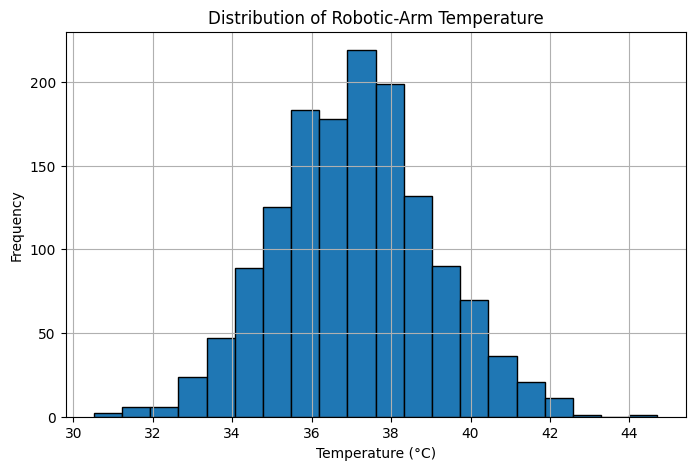

In [10]:
# Create a new figure for the temperature histogram.
plt.figure(figsize=(8, 5))

# Plot a histogram of temperature using 20 bins.
plt.hist(data["Temperature"], bins=20, edgecolor="black")

# Label the horizontal axis.
plt.xlabel("Temperature (°C)")

# Label the vertical axis.
plt.ylabel("Frequency")

# Add a meaningful title.
plt.title("Distribution of Robotic-Arm Temperature")

# Add grid lines to help read frequencies.
plt.grid(True)

# Display the histogram.
plt.show()


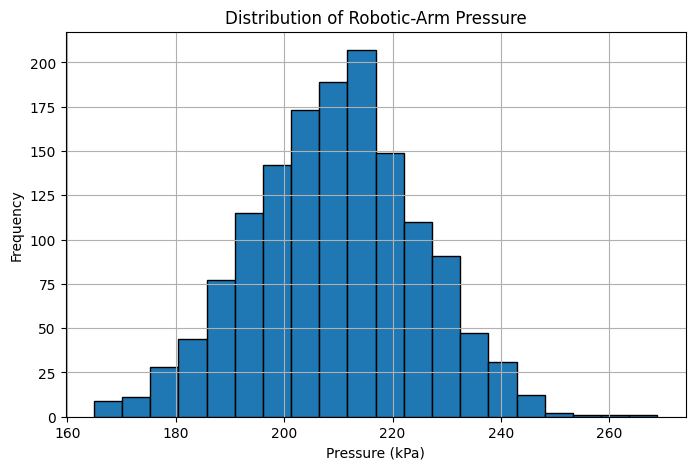

In [11]:
# Create a new figure for the pressure histogram.
plt.figure(figsize=(8, 5))

# Plot a histogram of pressure using 20 bins.
plt.hist(data["Pressure"], bins=20, edgecolor="black")

# Label the horizontal axis.
plt.xlabel("Pressure (kPa)")

# Label the vertical axis.
plt.ylabel("Frequency")

# Add a meaningful title.
plt.title("Distribution of Robotic-Arm Pressure")

# Add grid lines to help read frequencies.
plt.grid(True)

# Display the histogram.
plt.show()



### Questions to ask when reading a histogram

- Is the distribution approximately symmetrical?
- Is it right-skewed or left-skewed?
- Does it have one main peak or several peaks?
- Are there isolated values far from the main group?
- Could multiple peaks represent different machine operating modes?



## 7. Skewness and kurtosis

**Skewness** describes asymmetry:

- positive skewness → longer right tail;
- negative skewness → longer left tail;
- a value near zero → approximately symmetrical.

**Kurtosis** describes tail behaviour and the tendency to produce extreme observations.


In [12]:
# Calculate the skewness of the temperature distribution.
temperature_skewness = data["Temperature"].skew()

# Calculate the excess kurtosis of the temperature distribution.
temperature_kurtosis = data["Temperature"].kurt()

# Calculate the skewness of the pressure distribution.
pressure_skewness = data["Pressure"].skew()

# Calculate the excess kurtosis of the pressure distribution.
pressure_kurtosis = data["Pressure"].kurt()

# Display the temperature skewness.
print(f"Temperature skewness: {temperature_skewness:.3f}")

# Display the temperature excess kurtosis.
print(f"Temperature excess kurtosis: {temperature_kurtosis:.3f}")

# Display the pressure skewness.
print(f"Pressure skewness: {pressure_skewness:.3f}")

# Display the pressure excess kurtosis.
print(f"Pressure excess kurtosis: {pressure_kurtosis:.3f}")


Temperature skewness: 0.062
Temperature excess kurtosis: 0.007
Pressure skewness: -0.026
Pressure excess kurtosis: -0.026



### Important note about kurtosis in pandas

There are two common kurtosis conventions.

- Under the **Pearson convention**, a normal distribution has kurtosis **3**.
- pandas `.kurt()` reports **Fisher's excess kurtosis**, where the normal distribution has value **0**.

Therefore, when using pandas:

- excess kurtosis near 0 → similar tail behaviour to a normal distribution;
- positive value → heavier tails;
- negative value → lighter tails.

Always know which definition your software is using.



## 8. Statistical summary of the whole dataset

The pandas `.describe()` method gives several useful descriptive statistics in one table.


In [13]:
# Calculate and display the standard descriptive-statistics table.
print(data.describe())


              Time  Temperature    Vibration     Pressure
count  1440.000000  1440.000000  1440.000000  1440.000000
mean    719.500000    37.079688     0.030266   209.435010
std     415.836506     1.974666     0.009774    15.405650
min       0.000000    30.517465    -0.000195   164.885515
25%     359.750000    35.725049     0.023675   199.033123
50%     719.500000    37.093417     0.030035   209.468751
75%    1079.250000    38.341919     0.036726   219.501156
max    1439.000000    44.705463     0.061931   268.893566



### Summary of Part 1

You have used statistics to answer different engineering questions:

| Statistical concept | Example engineering question |
|---|---|
| Mean / Median | What is a typical operating value? |
| Mode | Which rounded or categorical value occurs most often? |
| Range | What is the total observed spread? |
| Variance / Standard deviation | How consistent are the measurements? |
| Quartiles / IQR | Where does the central 50% of the data lie? |
| 1.5 × IQR fences | Which readings are statistically unusual? |
| Histogram | What is the shape of the distribution? |
| Skewness | Is the distribution asymmetric? |
| Kurtosis | How heavy are the tails relative to a normal distribution? |



# Part 2 - Student Exercise

## Statistical assessment of robotic-arm sensor behaviour

Use `robotic_arm_large_data.csv`.

Complete the following tasks independently. You may refer back to Part 1 for syntax, but decide which variable and statistical method is required for each task.



### Task 1 - Load and check the data

1. Load the CSV file into a DataFrame called `exercise_data`.
2. Display the first five rows.
3. Display the shape of the dataset.
4. Confirm whether any values are missing.

**Hint:** Use `pd.read_csv()`, `.head()`, `.shape`, and `.isnull().sum()`.


In [14]:
# Write your code for Task 1 below.




### Task 2 - Central tendency of Pressure

Calculate:

1. mean pressure;
2. median pressure;
3. pressure rounded to the nearest whole kPa;
4. mode of the rounded pressure values.

Then answer:

**Are the mean and median close to each other? What does that suggest about the centre of the pressure distribution?**


In [15]:
# Write your code for Task 2 below.




**Write your interpretation here:**

-



### Task 3 - Variability of Temperature

Calculate the following for Temperature:

1. minimum;
2. maximum;
3. range;
4. population variance using `ddof=0`;
5. population standard deviation using `ddof=0`.

Print all results with suitable units.

**Hint:** Use `.min()`, `.max()`, `.var(ddof=0)`, and `.std(ddof=0)`.


In [16]:
# Write your code for Task 3 below.




### Task 4 - Quartiles and vibration outliers

For Vibration:

1. calculate Q1, Q2, and Q3;
2. calculate the IQR;
3. calculate the lower and upper 1.5 × IQR fences;
4. identify all potential outliers;
5. print the number of potential outliers.

**Hint:** Use the pressure example in Part 1 as a pattern.


In [17]:
# Write your code for Task 4 below.




### Task 5 - Visualise Vibration

Create a histogram of Vibration with:

- 20 bins;
- black bin edges;
- x-axis label with unit;
- y-axis label;
- meaningful title;
- grid lines.

Then describe the shape of the distribution in two or three sentences.

Consider:

- symmetry;
- skew;
- unusual values;
- whether there is one main peak.


In [18]:
# Write your code for Task 5 below.




**Write your histogram interpretation here:**

-



### Task 6 - Skewness and kurtosis of Vibration

1. Calculate vibration skewness.
2. Calculate vibration excess kurtosis using pandas.
3. Interpret both values.

**Hint:** Values close to zero suggest approximate symmetry and tail behaviour similar to a normal distribution.


In [19]:
# Write your code for Task 6 below.




**Write your interpretation here:**

-



### Task 7 - Engineering interpretation

Answer these questions in your own words.

1. Why is standard deviation usually easier to interpret than variance?
2. Why should an IQR outlier not automatically be deleted?
3. Why may mode be unsuitable for raw continuous sensor readings?
4. What could a bimodal histogram indicate in an industrial machine?
5. Why is it important to know whether software reports ordinary kurtosis or excess kurtosis?

**Write your answers here:**

1.  
2.  
3.  
4.  
5.  



## Optional challenge - Compare two operating periods

Split the 24-hour dataset into:

- **First 12 hours:** Time < 720
- **Second 12 hours:** Time ≥ 720

For each period, calculate:

- mean temperature;
- standard deviation of temperature.

Then compare the two periods.

**Question:** Does the second half of the day appear noticeably different from the first half based on these two statistics?

> This is an introductory comparison only. It is not a formal statistical significance test.


In [20]:
# Write your optional challenge code below.




# End-of-practical reflection

Before finishing, make sure you can explain:

- the difference between mean and median;
- when mode is useful and when it is not;
- the difference between range and standard deviation;
- what Q1, Q2, and Q3 represent;
- how the IQR rule identifies potential outliers;
- what a histogram tells you that a single average cannot;
- how to interpret positive and negative skewness;
- why pandas normal-distribution kurtosis is approximately zero.

### Save your work

Save your completed notebook. A separate worked solution to Part 2 can be used for comparison in the following session.
